# Random Forest Classifier — CUB-200-2011 Tabular Attributes

This notebook classifies 200 bird species from the 312 image-level attribute labels, using a Random Forest, and compares it with the single decision tree from [`decisionTree.ipynb`](decisionTree.ipynb).

**Input:** the feature files written by [`dataPrep.ipynb`](dataPrep.ipynb) (run that first).
**Protocol:** the same as the decision tree notebook, so the results are directly comparable:
- official train/test split (`SPLIT = 'is_train'`);
- grid search with stratified 5-fold CV on the **training set only**, using the same folds (`random_state = 42`);
- the test set is used once, at the end.

For the one-at-a-time validation curves we use the forest's **out-of-bag (OOB) score**. Each tree is scored on the roughly 37% of training images left out of its bootstrap sample. This gives an honest out-of-sample estimate from a single fit, about 5× cheaper than CV, without touching the test set. It is slightly pessimistic, because each image is scored by only the ~37% of trees that did not see it, so OOB is used to compare settings (relative differences), while CV is used for the final model choice.

| Step | Section |
|---|---|
| Baseline (default forest) | 2 |
| Number of trees (OOB curve) | 3 |
| Validation curves (OOB) | 4 |
| Grid search (5-fold CV) | 5 |
| Feature variant comparison (A / B / C) | 6 |
| Final test evaluation | 7 |
| Comparison with the decision tree | 8 |
| Error analysis | 9 |
| Feature importance | 10 |

## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix

RANDOM_STATE = 42
SPLIT = 'is_train'
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train']  # never used as features

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

def load_variant(name):
    """Return X_train, y_train, X_test, y_test for feature variant A, B or C."""
    path = DATA / f'cub_features_{name}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path)
    features = [c for c in df.columns if c not in META_COLS]
    train, test = df[df[SPLIT] == 1], df[df[SPLIT] == 0]
    return train[features], train.class_id, test[features], test.class_id

def oob_score(X, y, **params):
    rf = RandomForestClassifier(oob_score=True, random_state=RANDOM_STATE, n_jobs=-1, **params)
    return rf.fit(X, y).oob_score_

X_train, y_train, X_test, y_test = load_variant('A')
class_names = pd.read_csv(DATA / 'cub_features_A.csv', usecols=['class_id', 'class_name']) \
                .drop_duplicates().set_index('class_id').class_name.sort_index()

print('train', X_train.shape, '| test', X_test.shape, '| classes', y_train.nunique())

train (5994, 312) | test (5794, 312) | classes 200


## 2. Baseline: default Random Forest

The defaults are 100 trees, `max_features='sqrt'` (about 18 of the 312 features tried at each split), and fully grown trees. This baseline is the reference point that tuning has to beat. It is evaluated with the same 5-fold CV as the decision tree, so the two baselines are directly comparable.

In [2]:
baseline = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
cv_base = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)

print(f"train accuracy (CV folds): {cv_base['train_accuracy'].mean():.3f}")
print(f"CV accuracy:               {cv_base['test_accuracy'].mean():.3f} ± {cv_base['test_accuracy'].std():.3f}")
print(f"CV macro-F1:               {cv_base['test_f1_macro'].mean():.3f} ± {cv_base['test_f1_macro'].std():.3f}")

train accuracy (CV folds): 0.999
CV accuracy:               0.427 ± 0.008
CV macro-F1:               0.405 ± 0.009


## 3. How many trees?

Adding trees never causes overfitting. It only reduces variance, until the accuracy plateaus. So `n_estimators` is not tuned like the other hyperparameters. The question is simply how many trees are needed before accuracy stops improving. We grow one forest incrementally (`warm_start`) and track the OOB accuracy.

**Two tree counts are used, deliberately:**
- **Final model: the smallest count within 0.25 points of the best OOB score** (next cell). Beyond that point, extra trees only add runtime. 0.25 points is well below the CV fold noise (about 1 point), so the improvement given up is negligible.
- **Grid search and validation curves: 300 trees.** These need hundreds of fits, and 300 trees is already close to the plateau. More trees raise every configuration's score by a similar amount, so the *ranking* of configurations, which is all the search needs, is unaffected.

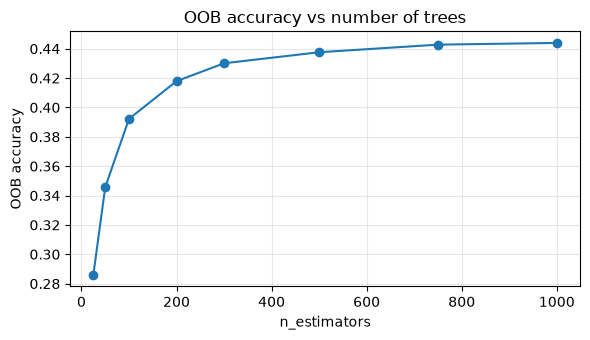

,25,50,100,200,300,500,750,1000
OOB accuracy,0.286,0.3457,0.3922,0.4179,0.4301,0.4376,0.4428,0.4439


In [3]:
tree_counts = [25, 50, 100, 200, 300, 500, 750, 1000]
oob_by_trees = {}
rf = RandomForestClassifier(warm_start=True, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
for n in tree_counts:
    rf.set_params(n_estimators=n).fit(X_train, y_train)
    oob_by_trees[n] = rf.oob_score_

oob_by_trees = pd.Series(oob_by_trees, name='OOB accuracy')
fig, ax = plt.subplots(figsize=(6, 3.5))
oob_by_trees.plot(ax=ax, marker='o')
ax.set(title='OOB accuracy vs number of trees', xlabel='n_estimators', ylabel='OOB accuracy')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
oob_by_trees.round(4).to_frame().T

In [4]:
# Smallest forest within 0.25 percentage points of the best OOB score: more trees beyond this only add runtime
FINAL_N_ESTIMATORS = int(oob_by_trees[oob_by_trees >= oob_by_trees.max() - 0.0025].index.min())
SEARCH_N_ESTIMATORS = 300  # used inside the grid search to keep runtime manageable
print('final n_estimators:', FINAL_N_ESTIMATORS)

final n_estimators: 750


## 4. Validation curves (OOB)

We vary one hyperparameter at a time (300 trees, other settings at their defaults), for both split criteria, to find the region worth grid-searching. These are the forest's main controls:
- `max_features`: how many features each split considers. Fewer features make the trees more different from each other; more make each tree stronger.
- `min_samples_leaf` and `max_depth`: how far each tree is allowed to grow.

OOB is used here because it needs one fit per point instead of five.

**Reading the curves:**
- Gini beats entropy by about 6 points at every setting.
- `max_features` peaks between `sqrt` and 0.2 (about 18–60 features) and falls off on both sides.
- `min_samples_leaf` is best at 1–2 and drops from 5 upwards.
- `max_depth` only hurts below about 15 and is flat from 20 upwards.

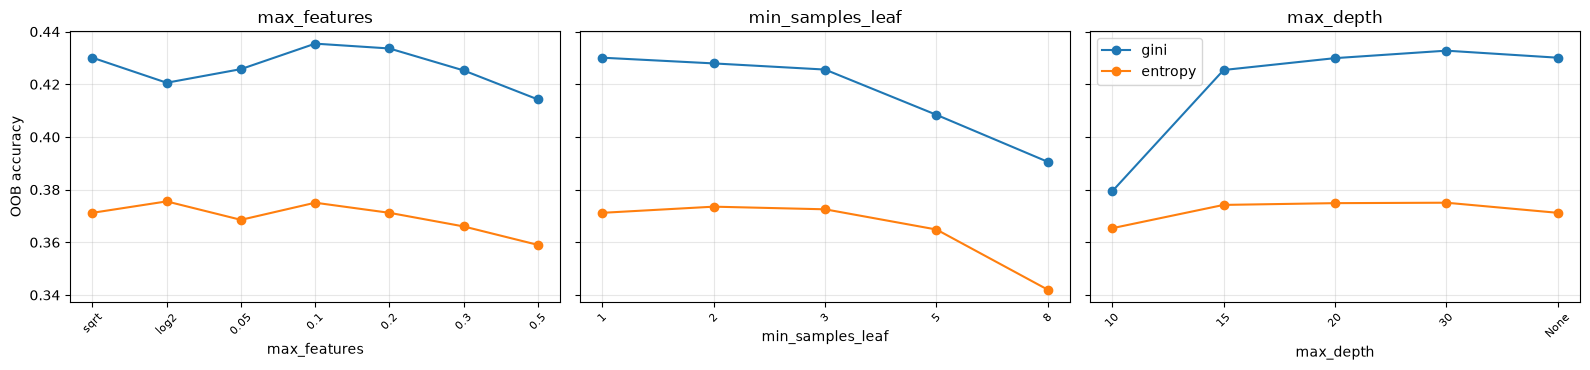

36s


max_features         min_samples_leaf         max_depth        
             gini entropy             gini entropy      gini entropy
sqrt       0.4301  0.3712              NaN     NaN       NaN     NaN
log2       0.4206  0.3755              NaN     NaN       NaN     NaN
0.05       0.4258  0.3685              NaN     NaN       NaN     NaN
0.1        0.4354  0.3750              NaN     NaN       NaN     NaN
0.2        0.4336  0.3712              NaN     NaN       NaN     NaN
0.3        0.4253  0.3660              NaN     NaN       NaN     NaN
0.5        0.4142  0.3590              NaN     NaN       NaN     NaN
1             NaN     NaN           0.4301  0.3712       NaN     NaN
2             NaN     NaN           0.4279  0.3735       NaN     NaN
3             NaN     NaN           0.4256  0.3725       NaN     NaN
5             NaN     NaN           0.4084  0.3649       NaN     NaN
8             NaN     NaN           0.3906  0.3420       NaN     NaN
10            NaN     NaN              NaN     NaN    0.3794  0.3654
15            NaN     NaN              NaN     NaN    0.4254  0.3742
20            NaN     NaN              NaN     NaN    0.4299  0.3749
30            NaN     NaN              NaN     NaN    0.4328  0.3750
None          NaN     NaN              NaN     NaN    0.4301  0.3712

In [5]:
curves = {
    'max_features': ['sqrt', 'log2', 0.05, 0.1, 0.2, 0.3, 0.5],
    'min_samples_leaf': [1, 2, 3, 5, 8],
    'max_depth': [10, 15, 20, 30, None],
}

t0 = time.time()
fig, axes = plt.subplots(1, len(curves), figsize=(16, 3.8), sharey=True)
curve_tables = {}
for ax, (param, values) in zip(axes, curves.items()):
    table = {}
    for criterion, colour in [('gini', 'tab:blue'), ('entropy', 'tab:orange')]:
        scores = [oob_score(X_train, y_train, n_estimators=SEARCH_N_ESTIMATORS,
                            criterion=criterion, **{param: v}) for v in values]
        table[criterion] = scores
        ax.plot(range(len(values)), scores, 'o-', color=colour, label=criterion)
    curve_tables[param] = pd.DataFrame(table, index=[str(v) for v in values]).round(4)
    ax.set_xticks(range(len(values)), [str(v) for v in values], rotation=45, fontsize=8)
    ax.set(title=param, xlabel=param)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('OOB accuracy')
axes[-1].legend()
plt.tight_layout()
plt.show()
print(f'{time.time() - t0:.0f}s')
pd.concat(curve_tables, axis=1)

## 5. Grid search (variant A, 5-fold CV)

**How the ranges were chosen from §4:**
- `max_features` ∈ {`sqrt`, 0.1, 0.2}: the peak region.
- `min_samples_leaf` ∈ {1, 2}: values of 3 or more were already worse.
- `max_depth` ∈ {30, `None`}: depth only matters below 15, so we only check whether capping very deep trees helps.
- The split criterion is kept in the grid even though entropy looked worse, so the final choice is justified by CV.

That gives 24 combinations × 5 folds, scored with the **same folds as the decision tree**.

**Implementation choices:**
- **Parallelism:** `n_jobs=-1` is set on the grid search and `n_jobs=1` on each forest. This runs one forest per CPU core, instead of nesting parallel jobs, which would oversubscribe the cores.
- **`refit=False`:** the grid search doesn't refit the best model itself. It is refit by hand in §7 with the final tree count from §3 rather than the 300 used for searching.

In [6]:
PARAM_GRID = {
    'criterion': ['gini', 'entropy'],
    'max_features': ['sqrt', 0.1, 0.2],
    'min_samples_leaf': [1, 2],
    'max_depth': [30, None],
}

def grid_search(X, y):
    rf = RandomForestClassifier(n_estimators=SEARCH_N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=1)
    gs = GridSearchCV(rf, PARAM_GRID, cv=CV, scoring=SCORING, refit=False, n_jobs=-1)
    return gs.fit(X, y)

def best_row(gs):
    i = int(np.argmin(gs.cv_results_['rank_test_accuracy']))
    r = gs.cv_results_
    return {'cv_accuracy': r['mean_test_accuracy'][i], 'cv_acc_std': r['std_test_accuracy'][i],
            'cv_f1_macro': r['mean_test_f1_macro'][i], **r['params'][i]}

def top_results(gs, n=8):
    res = pd.DataFrame(gs.cv_results_)
    cols = ['param_' + p for p in PARAM_GRID] + ['mean_test_accuracy', 'std_test_accuracy', 'mean_test_f1_macro']
    return res.sort_values('rank_test_accuracy')[cols].head(n).round(4)

t0 = time.time()
gs_A = grid_search(X_train, y_train)
print(f"{len(gs_A.cv_results_['params'])} combinations x {CV.get_n_splits()} folds in {time.time() - t0:.0f}s")
top_results(gs_A)

/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


24 combinations x 5 folds in 77s


,param_criterion,param_max_features,param_min_samples_leaf,param_max_depth,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
3,gini,0.1,2,30,0.4439,0.0120,0.4192
2,gini,0.1,1,30,0.4429,0.0149,0.4217
0,gini,sqrt,1,30,0.4424,0.0124,0.4191
1,gini,sqrt,2,30,0.4423,0.0100,0.4139
7,gini,sqrt,2,None,0.4408,0.0119,0.4131
8,gini,0.1,1,None,0.4406,0.0145,0.4184
9,gini,0.1,2,None,0.4403,0.0154,0.4160
4,gini,0.2,1,30,0.4381,0.0155,0.4171


## 6. Compare feature variants

We run the same grid on each "not visible" encoding (A: raw 0/1, B: −1/0/1, C: A + 28 not-visible flags). The single tree showed no measurable difference between them. A forest, which averages many trees, may be able to use the extra signal.

As in the decision tree notebook, each variant gets its own full grid search, and the highest mean CV accuracy is selected. The selection rule picks the top score mechanically. A lead smaller than the fold standard deviation (`cv_acc_std`) means the variants are effectively tied, and is reported as such in the summary.

In [7]:
searches = {'A': gs_A}
for name in ['B', 'C']:
    Xv, yv, _, _ = load_variant(name)
    searches[name] = grid_search(Xv, yv)

variant_table = pd.DataFrame({k: best_row(v) for k, v in searches.items()}).T
variant_table

/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,cv_accuracy,cv_acc_std,cv_f1_macro,criterion,max_depth,max_features,min_samples_leaf
A,0.443947,0.012047,0.419185,gini,30,0.1,2
B,0.435439,0.017007,0.412442,gini,30,0.1,1
C,0.445283,0.016645,0.417905,gini,30,sqrt,2


In [8]:
BEST_VARIANT = variant_table.cv_accuracy.astype(float).idxmax()
BEST_PARAMS = {k: v for k, v in best_row(searches[BEST_VARIANT]).items() if k in PARAM_GRID}
print(f'selected variant: {BEST_VARIANT}  params: {BEST_PARAMS}  n_estimators: {FINAL_N_ESTIMATORS}')

selected variant: C  params: {'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 2}  n_estimators: 750


## 7. Final evaluation on the test set

We refit the best configuration on the full training set, with the number of trees chosen in §3. This is the only time the test set is used. The OOB accuracy of the final model is reported as a sanity check: it should be close to the CV accuracy from the grid search. If it isn't, that would point to a problem with the refit.

In [9]:
X_train, y_train, X_test, y_test = load_variant(BEST_VARIANT)
model = RandomForestClassifier(n_estimators=FINAL_N_ESTIMATORS, oob_score=True,
                               random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

results = {
    'variant': BEST_VARIANT,
    'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
    'oob_accuracy': model.oob_score_,
    'cv_accuracy': best_row(searches[BEST_VARIANT])['cv_accuracy'],
    'test_accuracy': accuracy_score(y_test, y_pred),
    'test_f1_macro': f1_score(y_test, y_pred, average='macro'),
    'test_top5_accuracy': top_k_accuracy_score(y_test, proba, k=5, labels=model.classes_),
    'n_estimators': FINAL_N_ESTIMATORS,
}
pd.Series(results).to_frame('tuned random forest')

,tuned random forest
variant,C
train_accuracy,0.988989
oob_accuracy,0.435936
cv_accuracy,0.445283
test_accuracy,0.456334
test_f1_macro,0.434873
test_top5_accuracy,0.720573
n_estimators,750


## 8. Comparison with the decision tree

The tuned decision tree from `decisionTree.ipynb` turned out to be the default unpruned tree on variant A, so we refit it here with the same settings.

**Why the two models use different variants:** each model is compared in its **best tuned form**. The choice of feature variant was part of each model's tuning (and done on CV only), just like its hyperparameters. Both variants contain the same images in the same order, which the code checks, so the predictions can be paired image by image.

**Why McNemar's test:** both models are evaluated on the *same* test images, so their errors are paired, not independent. A simple comparison of two accuracies would ignore that pairing. McNemar's test uses only the images where exactly one of the two models is correct. If the models were equally good, those images would split roughly 50/50 between them. The exact binomial version is used, because it needs no large-sample approximation.

In [10]:
Xa_train, ya_train, Xa_test, ya_test = load_variant('A')
tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xa_train, ya_train)
tree_pred = tree.predict(Xa_test)
tree_proba = tree.predict_proba(Xa_test)
tree_cv = cross_validate(DecisionTreeClassifier(random_state=RANDOM_STATE), Xa_train, ya_train,
                         cv=CV, scoring='accuracy')['test_score'].mean()

comparison = pd.DataFrame({
    'decision tree': [accuracy_score(ya_test, tree_pred), f1_score(ya_test, tree_pred, average='macro'),
                      top_k_accuracy_score(ya_test, tree_proba, k=5, labels=tree.classes_)],
    'random forest': [results['test_accuracy'], results['test_f1_macro'], results['test_top5_accuracy']],
}, index=['test accuracy', 'test macro-F1', 'test top-5 accuracy'])
comparison['improvement'] = comparison['random forest'] - comparison['decision tree']
display(comparison.round(4))

# McNemar's exact test (both test sets contain the same images in the same order)
assert (ya_test.values == y_test.values).all()
tree_right, forest_right = tree_pred == ya_test.values, y_pred == y_test.values
only_forest, only_tree = int((forest_right & ~tree_right).sum()), int((tree_right & ~forest_right).sum())
p = binomtest(only_tree, only_tree + only_forest, 0.5).pvalue
print(f'only forest correct: {only_forest}, only tree correct: {only_tree}, McNemar exact p = {p:.2e}')

,decision tree,random forest,improvement
test accuracy,0.2468,0.4563,0.2095
test macro-F1,0.2452,0.4349,0.1896
test top-5 accuracy,0.2635,0.7206,0.4570


only forest correct: 1424, only tree correct: 210, McNemar exact p = 1.40e-221


## 9. Error analysis

The same analysis as for the decision tree, so the two can be compared:
- the most frequently confused species pairs, which show whether the errors are between genuinely similar species;
- best and worst species by F1.

In addition, per-species F1 is plotted **against the tree's**. Each point is a species, and points above the diagonal improved. This shows whether the forest's gain is broad (most species improve) or concentrated in a few species.

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
np.fill_diagonal(cm, 0)  # keep only misclassifications
off = pd.DataFrame(cm, index=model.classes_, columns=model.classes_)
pairs = (off.stack().rename('count').reset_index()
           .rename(columns={'level_0': 'true', 'level_1': 'predicted'})
           .sort_values('count', ascending=False).head(15))
pairs['true'] = pairs.true.map(class_names)
pairs['predicted'] = pairs.predicted.map(class_names)
pairs.reset_index(drop=True)

,true,predicted,count
0,030.Fish_Crow,029.American_Crow,16
1,054.Blue_Grosbeak,014.Indigo_Bunting,15
2,107.Common_Raven,029.American_Crow,14
3,112.Great_Grey_Shrike,111.Loggerhead_Shrike,13
4,029.American_Crow,030.Fish_Crow,11
5,144.Common_Tern,141.Artic_Tern,11
6,184.Louisiana_Waterthrush,183.Northern_Waterthrush,10
7,150.Sage_Thrasher,149.Brown_Thrasher,9
8,074.Florida_Jay,164.Cerulean_Warbler,9
9,025.Pelagic_Cormorant,023.Brandt_Cormorant,8


Best classified species (forest):
048.European_Goldfinch           0.931
189.Red_bellied_Woodpecker       0.879
057.Rose_breasted_Grosbeak       0.875
188.Pileated_Woodpecker          0.870
191.Red_headed_Woodpecker        0.844
012.Yellow_headed_Blackbird      0.842
083.White_breasted_Kingfisher    0.776
007.Parakeet_Auklet              0.760

Worst classified species (forest):
039.Least_Flycatcher             0.000
040.Olive_sided_Flycatcher       0.000
043.Yellow_bellied_Flycatcher    0.000
131.Vesper_Sparrow               0.000
173.Orange_crowned_Warbler       0.000
179.Tennessee_Warbler            0.043
153.Philadelphia_Vireo           0.045
124.Le_Conte_Sparrow             0.049

species improved over the tree: 183 / 200, worse: 14


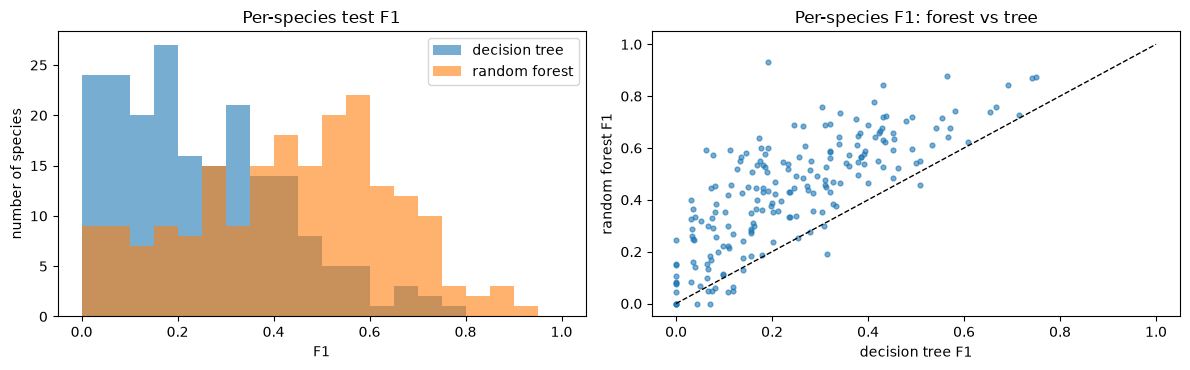

In [12]:
labels = class_names.loc[model.classes_].values
f1_forest = pd.Series(f1_score(y_test, y_pred, average=None, labels=model.classes_), index=labels)
f1_tree = pd.Series(f1_score(ya_test, tree_pred, average=None, labels=model.classes_), index=labels)

print('Best classified species (forest):');  print(f1_forest.nlargest(8).round(3).to_string())
print('\nWorst classified species (forest):'); print(f1_forest.nsmallest(8).round(3).to_string())
print(f'\nspecies improved over the tree: {(f1_forest > f1_tree).sum()} / {len(labels)}, '
      f'worse: {(f1_forest < f1_tree).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 1, 21)
axes[0].hist(f1_tree, bins=bins, alpha=0.6, label='decision tree')
axes[0].hist(f1_forest, bins=bins, alpha=0.6, label='random forest')
axes[0].set(title='Per-species test F1', xlabel='F1', ylabel='number of species')
axes[0].legend()
axes[1].scatter(f1_tree, f1_forest, s=12, alpha=0.6)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set(title='Per-species F1: forest vs tree', xlabel='decision tree F1', ylabel='random forest F1')
plt.tight_layout()
plt.show()

## 10. Feature importance

**Impurity-based importance** (mean decrease in impurity) is computed during training, but it is known to be biased towards frequently split features. **Permutation importance** is more reliable: shuffle a feature and measure the drop in accuracy. Because each body part is one-hot encoded across many columns, we permute each **attribute group** as a whole (all columns of e.g. `has_wing_color` together). This asks how much accuracy is lost without the wing colour information.

Permutation importance is computed on the test set purely for interpretation. Nothing is tuned from it.

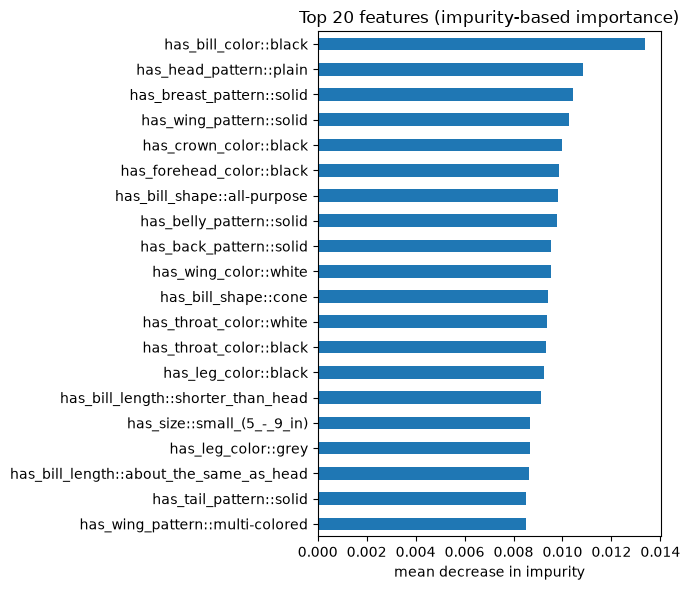

In [13]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)

fig, ax = plt.subplots(figsize=(7, 6))
importances.nlargest(20).sort_values().plot.barh(ax=ax, color='tab:blue')
ax.set(title='Top 20 features (impurity-based importance)', xlabel='mean decrease in impurity')
plt.tight_layout()
plt.show()

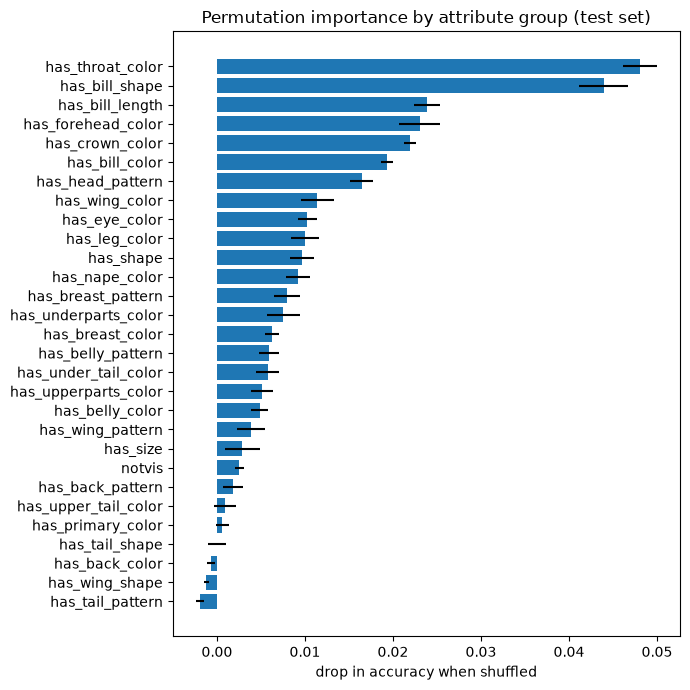

,accuracy drop,std
has_throat_color,0.0481,0.0019
has_bill_shape,0.0439,0.0028
has_bill_length,0.0238,0.0015
has_forehead_color,0.0230,0.0023
has_crown_color,0.0219,0.0007
has_bill_color,0.0193,0.0007
has_head_pattern,0.0164,0.0013
has_wing_color,0.0114,0.0019
has_eye_color,0.0103,0.0011
has_leg_color,0.0100,0.0016


In [14]:
rng = np.random.default_rng(RANDOM_STATE)
groups = X_test.columns.str.split('::').str[0]
base_acc = results['test_accuracy']
N_REPEATS = 5

drops = {}
for group in pd.unique(groups):
    cols = X_test.columns[groups == group]
    scores = []
    for _ in range(N_REPEATS):
        X_perm = X_test.copy()
        X_perm[cols] = X_test[cols].values[rng.permutation(len(X_test))]  # shuffle rows of the whole group together
        scores.append(base_acc - accuracy_score(y_test, model.predict(X_perm)))
    drops[group] = (np.mean(scores), np.std(scores))

group_perm = pd.DataFrame(drops, index=['accuracy drop', 'std']).T.sort_values('accuracy drop')
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(group_perm.index, group_perm['accuracy drop'], xerr=group_perm['std'], color='tab:blue')
ax.set(title='Permutation importance by attribute group (test set)', xlabel='drop in accuracy when shuffled')
plt.tight_layout()
plt.show()
group_perm.sort_values('accuracy drop', ascending=False).head(10).round(4)

**Reading the importances. Why do tail and wing attributes matter least?** The groups with near-zero permutation importance (tail shape/pattern, wing shape, back colour) are also the ones most often marked *not visible* (22–35% of images in `dataPrep.ipynb` §9). They are often missing or guessed, so the forest learns to rely on the head and bill instead.

## 11. Summary

The headline numbers for the report:

In [15]:
summary = comparison.copy()
summary.loc['CV accuracy (train, 5-fold)'] = [tree_cv, results['cv_accuracy'], results['cv_accuracy'] - tree_cv]
summary.round(4)

,decision tree,random forest,improvement
test accuracy,0.2468,0.4563,0.2095
test macro-F1,0.2452,0.4349,0.1896
test top-5 accuracy,0.2635,0.7206,0.4570
"CV accuracy (train, 5-fold)",0.2466,0.4453,0.1987


In [16]:
print('selected variant:', BEST_VARIANT)
print('selected hyperparameters:', {**BEST_PARAMS, 'n_estimators': FINAL_N_ESTIMATORS})

selected variant: C
selected hyperparameters: {'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 750}


**Findings (with `RANDOM_STATE = 42`):**
- The forest reaches **45.6% test accuracy** (macro-F1 0.435), against **24.7%** for the single decision tree: an absolute gain of about 21 percentage points. McNemar's test confirms the difference is highly significant (1,424 test images only the forest gets right vs 210 only the tree gets right, p ≈ 1e-221). The forest improves 183 of the 200 species.
- **Top-5 accuracy is 72.1%** (tree: 26.4%). Averaging hundreds of trees gives meaningful probabilities, so the correct species is usually among the top few guesses even when the first guess is wrong. These near-misses are mostly lookalike species.
- **Hyperparameters:** gini clearly beats entropy (about 6 points OOB). `max_features` around `sqrt`–0.2 and `min_samples_leaf` of 1–2 are best. Depth only matters below about 15. The top grid configurations are all within about 0.5 points of each other, so the forest is not sensitive to tuning in this region. Accuracy plateaus at about 750 trees.
- **Overfitting is much smaller in effect:** train accuracy is still about 99%, but CV/OOB accuracy rose from about 25% to about 44%. Averaging decorrelated trees removes most of the single tree's variance.
- **Feature variants:** C (0.445) ≈ A (0.444) > B (0.435) in CV accuracy. C was selected, but its lead over A (0.13 points) is far smaller than the fold standard deviation (about 1.2–1.7 points). So, as with the decision tree, explicitly encoding "not visible" brings **no measurable benefit**. The permutation importance of all 28 `notvis` flags together is only about 0.25 points.
- **Errors are lookalike species:** Fish vs American Crow, Blue Grosbeak vs Indigo Bunting, Common Raven vs American Crow, the two shrikes, and the terns and waterthrushes. The worst classes are drab flycatchers, sparrows and warblers, which are hard to tell apart even for humans using these attributes.
- **Most important attribute groups (permutation):** throat colour, bill shape, bill length, forehead and crown colour, and bill colour. The head and bill dominate. Tail and wing shape and pattern contribute almost nothing.

## 12. Limitations

- **Single seed:** all results use `RANDOM_STATE = 42`. The fold standard deviation (about 1–1.7 points) shows the CV noise, but variation across seeds was not measured. The forest's randomness (bootstrap samples, feature subsets) makes this more relevant than for the single tree, although 750 trees keep it small.
- **Tree count used in the search:** the grid search used 300 trees, while the final model has 750. This assumes the ranking of configurations doesn't change with more trees, which is reasonable given the plateau in §3, but it wasn't verified.
- **Permutation importance on the test set:** this is standard for interpretation, but it means the importance figures describe this particular test set. Nothing was tuned on them.
- **Label noise and identical vectors:** a single annotator per image, and 16 groups of identical feature vectors with different species, put a ceiling on any tabular model.
- **Untested cleaning option:** the "drop guessing positives" switch in `dataPrep.ipynb` was not evaluated.